# Data quality analysis
This notebook does an analysis of the data quality of each dataset, and goes through measures to handle data quality issues such as duplicates, missing values, wrong formats etc.  

The notebook follows a structure where each dataset is analysed by first doing a qualitiative assesment, and then a quantitative assessment by checking the actual contents of data.

**AI notice:** The code in this notebook is created with assistance by the GitHub Copilot AI. All generated code has been manually validated and/or corrected by the researcher to make sure it serves the intended purpose.

### General focus and aim
- Focus on these data:
    - Actual, departed trains (thus exclude cancelled trains)
    - Time period of analysis, limited by findings of data exploration: 01-08-2025 to 16-09-2026
- Aim to do these types of analytics:
    - Short analysis of departure delays compared to all departed trains
    - More thorough analysis of departure delays, isolated
        - Delay reason codes (Årsakskoder)
        - Also try: Which sub-processes stands for most delay?

### Quantitative analysis content:
- Data types/formats
    - For each relevant, chosen columns ^^
- Expected dates for analysis period
    - All dates covered?
    - Any gaps in the middle of the study period?
- Row level contents
    - Blank rows?
    - Duplicate rows?
    - Rows w/o train ID (Tognummer)?
    - Planned departures w/o actual departure times?
    - Actual departures w/o planned departure?
- Column level contents - missing values
    - For each relevant, chosen column ^^
    - (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code)
- Grain uniqueness and duplicates
    - LoggTogID
- Scope of edge cases
    - Overnight departures
    - Outliers
        - Very large delays
        - Very early departures (deviation from planned)

## Import of programming packages

In [107]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## bronze_tp_operating_train_routes_ALB

### Qualitative aspects

**Data collection procedure:** 
- A -- Bronze dataset apparently based on OTR data (Operating Train Routes), provided by Vygruppen (according to a medallion dataset architecture). Should be automatically generated data, but formatted after staging area. Only filtered to CargoNets trains at Alnabru. Contains *all* of CargoNet registrered train arrivals and departures at Alnabru.
- B -- Data pulled from electronic systems, should have no manual data inputs.

**Comment:**
- A & B -- No manual data means less vulnerable to human typos etc.
- As these data contains a lot of automatically, "real" electronic input data, the dataset might be able to filter out all cancelled trains (which shouldn't be included in the analysis)
- This dataset should theoretically have the "facts" for which trains departed, and which ones were cancelled

**Relevant columns to use:**
- `train_id`
- `train_date`
- `cancelled`
- `scheduled_departure_time`
- `actual_departure_time`
- `actual_arrival_time`
- `estimated_arrival_time`
- `just_passing_through`
- `departure_delay`
- `train_company`

### Quantitative aspects

#### Preparation

In [108]:
# Import
df_vy_alnabru_timings = pd.read_csv("../data/bronze_tp_operating_train_routes_ALB.csv", sep=";", encoding="utf-8-sig")


In [109]:
# Define the inclusive date interval
start_date = pd.Timestamp("2025-08-01")
end_date = pd.Timestamp("2026-09-16")

# Convert Avgangsdato in the dataframe to a usable format
df_vy_alnabru_timings["train_date"] = pd.to_datetime(
    df_vy_alnabru_timings["train_date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Filter the dataset based on time period
df_vy_timings_filtered = (
    df_vy_alnabru_timings[
        df_vy_alnabru_timings["train_date"].between(
            start_date,
            end_date,
            inclusive="both"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

In [110]:
print("Number of rows:", len(df_vy_timings_filtered))
print(
    "Date range:",
    df_vy_timings_filtered["train_date"].min(),
    "to",
    df_vy_timings_filtered["train_date"].max()
)
print(df_vy_timings_filtered["train_date"].dtype)

Number of rows: 19952
Date range: 2025-08-01 00:00:00 to 2026-09-16 00:00:00
datetime64[us]


In [111]:
# Select the relevant columns for further analysis
relevant_columns = [
    "train_id",
    "train_date",
    "cancelled",
    "scheduled_departure_time",
    "actual_departure_time",
    "actual_arrival_time",
    "estimated_arrival_time",
    "just_passing_through",
    "departure_delay",
    "train_company"
]

df_vy_timings_filtered = (
    df_vy_timings_filtered[relevant_columns]
    .copy()
)

In [112]:
# Check filtering
print("Dimensions of filtered table:", df_vy_timings_filtered.shape)
df_vy_timings_filtered.columns.tolist()

Dimensions of filtered table: (19952, 10)


['train_id',
 'train_date',
 'cancelled',
 'scheduled_departure_time',
 'actual_departure_time',
 'actual_arrival_time',
 'estimated_arrival_time',
 'just_passing_through',
 'departure_delay',
 'train_company']

In [113]:
# Constructing the LoggTogID column
df_vy_timings_filtered["LoggTogID"] = (
    df_vy_timings_filtered["train_date"].dt.strftime("%d-%m-%Y")
    + "_"
    + df_vy_timings_filtered["train_id"].astype(str)
)

df_vy_timings_filtered[["train_id", "train_date", "LoggTogID"]].head()

,train_id,train_date,LoggTogID
0,21524,2026-09-16,16-09-2026_21524
1,21525,2026-09-16,16-09-2026_21525
2,21526,2026-09-16,16-09-2026_21526
3,21527,2026-09-16,16-09-2026_21527
4,21571,2026-09-16,16-09-2026_21571


*Comment:* Analysis should not use cancelled trains or trains just passing through, and should only be CargoNet trains

In [114]:
# Checking if it only contains CargoNet trains
df_vy_timings_filtered["train_company"].value_counts(dropna=False)

train_company
CN    19952
Name: count, dtype: int64

In [115]:
# Checking values of cancelled
df_vy_timings_filtered["cancelled"].value_counts(dropna=False)

cancelled
N    16644
Y     2445
P      863
Name: count, dtype: int64

In [116]:
# Checking values of just_passing_through
df_vy_timings_filtered["just_passing_through"].value_counts(dropna=False)

just_passing_through
False    12127
True      7825
Name: count, dtype: int64

In [117]:
# Collect cancelled trains in a separate table (for later use)
df_vy_cancelled_trains = df_vy_timings_filtered[
    df_vy_timings_filtered["cancelled"] == "Y"
].copy()

# Filter out cancelled trains and just_passing_through trains
df_vy_timings_filtered = df_vy_timings_filtered[
    (df_vy_timings_filtered["cancelled"] == "N") &
    (df_vy_timings_filtered["just_passing_through"] == False)
].copy()

# Identify rows that contain arrival information but no departure information
has_arrival_time = (
    df_vy_timings_filtered["actual_arrival_time"].notna() |
    df_vy_timings_filtered["estimated_arrival_time"].notna()
)
has_departure_time = (
    df_vy_timings_filtered["scheduled_departure_time"].notna() |
    df_vy_timings_filtered["actual_departure_time"].notna()
)

arrival_only_trains = df_vy_timings_filtered[
    has_arrival_time & ~has_departure_time
].copy()

print("Arrival-only trains before removal:", len(arrival_only_trains))

# Check whether rows missing departure times have arrival times
missing_departure_rows = df_vy_timings_filtered[~has_departure_time].copy()
missing_departure_summary = pd.Series({
    "Rows missing both departure times": len(missing_departure_rows),
    "Missing departure rows with arrival time": (
        has_arrival_time[~has_departure_time].sum()
    ),
    "Missing departure rows without arrival time": (
        (~has_arrival_time[~has_departure_time]).sum()
    )
})
missing_departure_summary

missing_departure_with_arrival = missing_departure_rows[
    has_arrival_time[~has_departure_time]
].copy()

missing_departure_without_arrival = missing_departure_rows[
    ~has_arrival_time[~has_departure_time]
].copy()

# Keep rows relevant to departure analysis; retain rows without timestamps
# for the separate missing-value assessment below.
df_vy_timings_filtered = df_vy_timings_filtered[
    ~(
        df_vy_timings_filtered["actual_arrival_time"].notna() |
        df_vy_timings_filtered["estimated_arrival_time"].notna()
    ) |
    has_departure_time
].copy()

Arrival-only trains before removal: 4597


In [118]:
# Checking cancelled values after filtering
df_vy_timings_filtered["cancelled"].value_counts(dropna=False)

cancelled
N    4968
Name: count, dtype: int64

In [119]:
# Checking values of just_passing_through after filtering
df_vy_timings_filtered["just_passing_through"].value_counts(dropna=False)

just_passing_through
False    4968
Name: count, dtype: int64

In [120]:
# Double check filtering
print("Dimensions of filtered table:", df_vy_timings_filtered.shape)
df_vy_timings_filtered.columns.tolist()

Dimensions of filtered table: (4968, 11)


['train_id',
 'train_date',
 'cancelled',
 'scheduled_departure_time',
 'actual_departure_time',
 'actual_arrival_time',
 'estimated_arrival_time',
 'just_passing_through',
 'departure_delay',
 'train_company',
 'LoggTogID']

#### Actual analysis

##### Expected dates for analysis period
- All dates covered?
- Any gaps in the middle of the study period?

In [121]:
# Define a function for use multiple times
def check_date_coverage(df, date_column, start_date, end_date, label):
    dates = pd.to_datetime(
        df[date_column],
        errors="coerce"
    ).dt.normalize()

    expected_dates = pd.date_range(
        start=start_date,
        end=end_date,
        freq="D"
    )

    observed_dates = pd.DatetimeIndex(
        dates.dropna().unique()
    ).sort_values()

    missing_dates = expected_dates.difference(observed_dates)

    daily_counts = (
        dates
        .value_counts()
        .reindex(expected_dates, fill_value=0)
        .sort_index()
        .rename("number_of_rows")
        .to_frame()
    )

    print(f"\n{label}")
    print("-" * len(label))
    print(f"Rows: {len(df)}")
    print(f"Rows with missing dates: {dates.isna().sum()}")
    print(f"Dates represented: {len(observed_dates)} of {len(expected_dates)}")
    print(f"Dates with no records: {len(missing_dates)}")

    if len(missing_dates) > 0:
        print("Missing dates:")
        print(missing_dates.strftime("%Y-%m-%d").tolist())
    else:
        print("All dates in the analysis period are represented.")

    return daily_counts, missing_dates

In [122]:
cancelled_daily_counts, cancelled_missing_dates = check_date_coverage(
    df=df_vy_cancelled_trains,
    date_column="train_date",
    start_date=start_date,
    end_date=end_date,
    label="Cancelled trains"
)

retained_daily_counts, retained_missing_dates = check_date_coverage(
    df=df_vy_timings_filtered,
    date_column="train_date",
    start_date=start_date,
    end_date=end_date,
    label="Retained trains"
)


Cancelled trains
----------------
Rows: 2445
Rows with missing dates: 0
Dates represented: 397 of 412
Dates with no records: 15
Missing dates:
['2025-12-10', '2025-12-17', '2025-12-18', '2026-01-13', '2026-01-14', '2026-01-15', '2026-01-22', '2026-02-10', '2026-02-24', '2026-03-10', '2026-03-18', '2026-05-19', '2026-06-18', '2026-09-03', '2026-09-08']

Retained trains
---------------
Rows: 4968
Rows with missing dates: 0
Dates represented: 406 of 412
Dates with no records: 6
Missing dates:
['2025-12-24', '2025-12-31', '2026-04-02', '2026-04-03', '2026-04-04', '2026-04-05']


*Comment:* After double-checking the internal CargoNet terminal logs, on the 4th and 5th of april all trains were cancelled. Thus, missing these dates in the 'departued'-table is ok

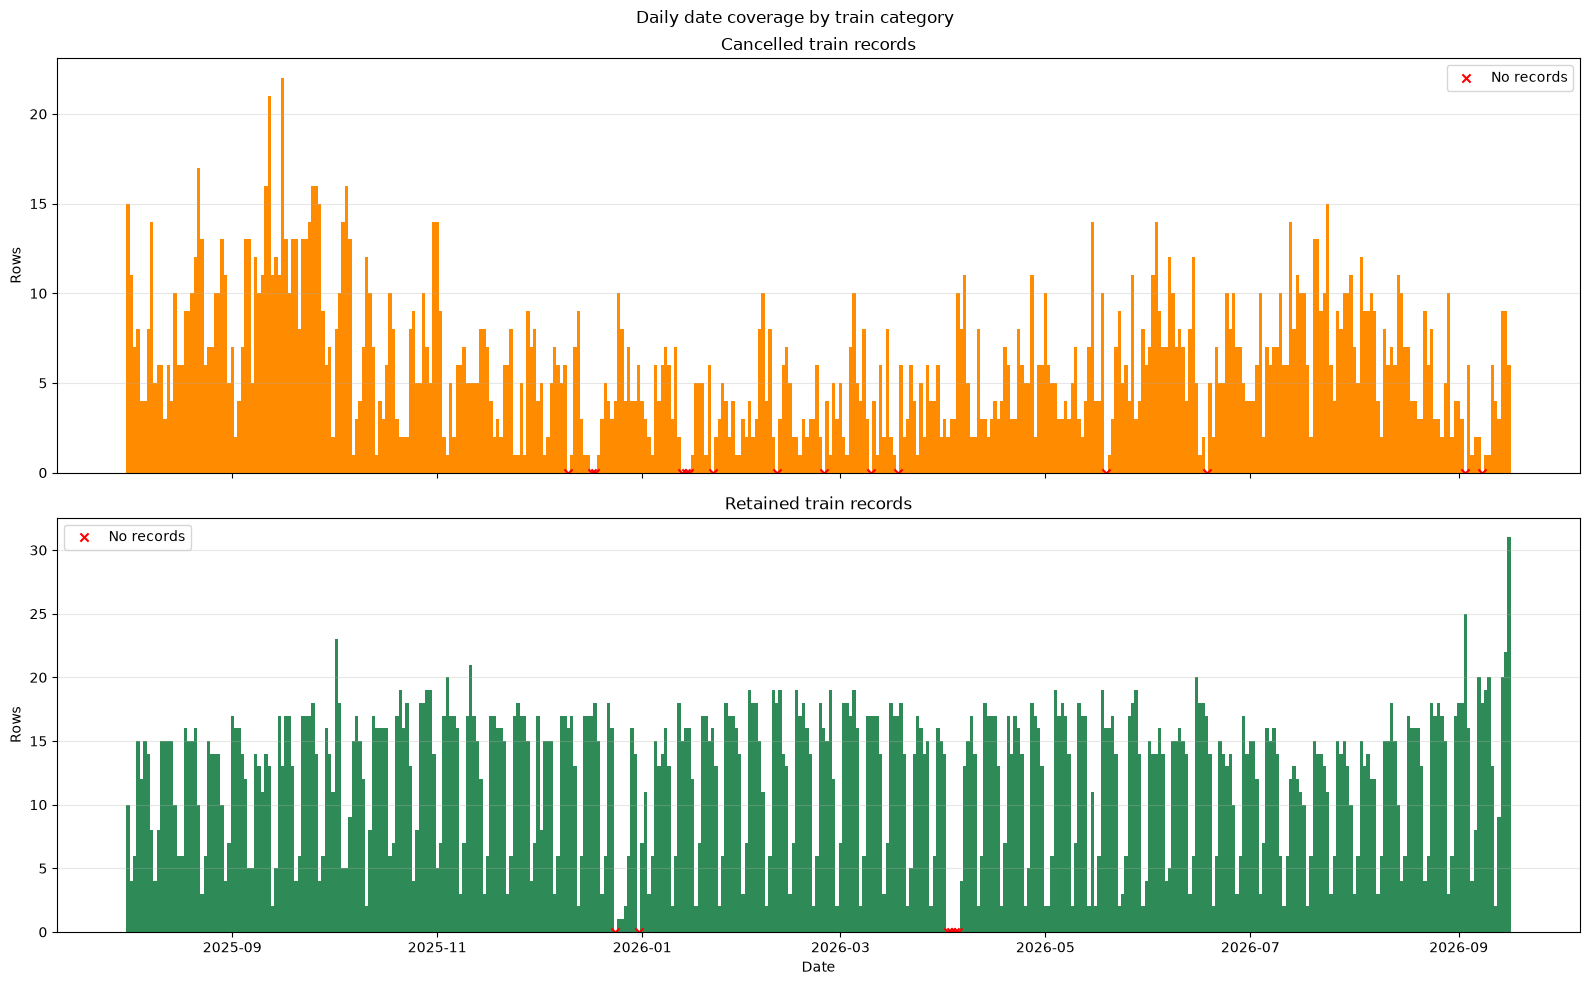

In [123]:
# Visualize the data

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(16, 10),
    sharex=True
)

datasets = [
    ("Cancelled train records", cancelled_daily_counts, "darkorange"),
    ("Retained train records", retained_daily_counts, "seagreen")
]

for ax, (label, daily_counts, color) in zip(axes, datasets):
    ax.bar(
        daily_counts.index,
        daily_counts["number_of_rows"],
        width=1.0,
        color=color
    )

    zero_dates = daily_counts.index[
        daily_counts["number_of_rows"] == 0
    ]

    ax.scatter(
        zero_dates,
        [0] * len(zero_dates),
        color="red",
        marker="x",
        s=35,
        label="No records"
    )

    ax.set_ylabel("Rows")
    ax.set_title(label)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Date")

plt.suptitle("Daily date coverage by train category")
plt.tight_layout()
plt.show()

##### Row level contents
- Duplicate rows?
- Blank rows?
- Rows w/o train ID (Tognummer)?
- Planned departures w/o actual departure times?
- Actual departures w/o planned departure?

- Arrival-only trains are identified separately using arrival timestamps and excluded from the departure analysis.

*Note: Checking only the departured trains, not the cancelled ones*

In [124]:
# Duplicate rows
duplicate_rows = df_vy_timings_filtered[
    df_vy_timings_filtered.duplicated(keep=False)
]

print(f"Number of duplicate rows: {len(duplicate_rows)}")
duplicate_rows

Number of duplicate rows: 0


,train_id,train_date,cancelled,scheduled_departure_time,actual_departure_time,actual_arrival_time,estimated_arrival_time,just_passing_through,departure_delay,train_company,LoggTogID


In [125]:
# Blank rows
blank_rows = df_vy_timings_filtered[
    df_vy_timings_filtered
    .replace(r"^\s*$", pd.NA, regex=True)
    .isna()
    .all(axis=1)
]

print(f"Number of blank rows: {len(blank_rows)}")

Number of blank rows: 0


In [126]:
# Comparing planned times vs. registered times
scheduled_missing = df_vy_timings_filtered["scheduled_departure_time"].isna()
actual_missing = df_vy_timings_filtered["actual_departure_time"].isna()

# Planned departure exists, but actual departure is missing
planned_without_actual = df_vy_timings_filtered[
    ~scheduled_missing & actual_missing
]

# Actual departure exists, but planned departure is missing
actual_without_planned = df_vy_timings_filtered[
    scheduled_missing & ~actual_missing
]

print(
    "Planned departures without actual departure:",
    len(planned_without_actual)
)

print(
    "Actual departures without planned departure:",
    len(actual_without_planned)
)

Planned departures without actual departure: 151
Actual departures without planned departure: 1


In [127]:
planned_without_actual[
    [
        "LoggTogID",
        "train_id",
        "train_date",
        "scheduled_departure_time",
        "actual_departure_time"
    ]
]

,LoggTogID,train_id,train_date,scheduled_departure_time,actual_departure_time
20,16-09-2026_41900,41900,2026-09-16,2026-09-16T18:26:00.000Z,NaN
22,16-09-2026_41910,41910,2026-09-16,2026-09-16T16:25:00.000Z,NaN
24,16-09-2026_41960,41960,2026-09-16,2026-09-16T15:28:00.000Z,NaN
29,16-09-2026_5301,5301,2026-09-16,2026-09-16T06:51:00.000Z,NaN
40,16-09-2026_5707,5707,2026-09-16,2026-09-16T15:12:00.000Z,NaN
...,...,...,...,...,...
17487,16-09-2025_22918,22918,2025-09-16,2025-09-16T08:58:00.000Z,NaN
17552,15-09-2025_21912,21912,2025-09-15,2025-09-15T07:58:00.000Z,NaN
18891,21-08-2025_21910,21910,2025-08-21,2025-08-21T12:10:00.000Z,NaN
19115,18-08-2025_41910,41910,2025-08-18,2025-08-18T16:25:00.000Z,NaN


In [128]:
actual_without_planned[
    [
        "LoggTogID",
        "train_id",
        "train_date",
        "scheduled_departure_time",
        "actual_departure_time"
    ]
]

,LoggTogID,train_id,train_date,scheduled_departure_time,actual_departure_time
3001,17-07-2026_8266,8266,2026-07-17,NaN,2026-07-17T23:55:00.000Z


##### Column level contents - missing values
- For each relevant, chosen column ^^
- (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code, or arrival trains having no departure times)

In [129]:
df_check = df_vy_timings_filtered.copy()

df_check = df_check.replace(r"^\s*$", pd.NA, regex=True)

missing_summary = pd.DataFrame({
    "missing_count": df_check.isna().sum(),
    "missing_percentage": (
        df_check.isna().mean() * 100
    ).round(2),
    "data_type": df_check.dtypes.astype(str)
})

missing_summary

,missing_count,missing_percentage,data_type
train_id,0,0.00,int64
train_date,0,0.00,datetime64[us]
cancelled,0,0.00,str
scheduled_departure_time,114,2.29,str
actual_departure_time,264,5.31,str
actual_arrival_time,4897,98.57,str
estimated_arrival_time,4923,99.09,str
just_passing_through,0,0.00,bool
departure_delay,265,5.33,float64
train_company,0,0.00,str


In [130]:
# Check combinations of missing departure times
scheduled_missing = (
    df_check["scheduled_departure_time"].isna()
)

actual_missing = (
    df_check["actual_departure_time"].isna()
)

departure_time_completeness = pd.Series({
    "Both departure times present": (
        ~scheduled_missing & ~actual_missing
    ).sum(),
    "Scheduled present, actual missing": (
        ~scheduled_missing & actual_missing
    ).sum(),
    "Actual present, scheduled missing": (
        scheduled_missing & ~actual_missing
    ).sum(),
    "Both departure times missing": (
        scheduled_missing & actual_missing
    ).sum()
})

departure_time_completeness

Both departure times present         4703
Scheduled present, actual missing     151
Actual present, scheduled missing       1
Both departure times missing          113
dtype: int64

In [131]:
departure_delay_missing = (
    df_check["scheduled_departure_time"].notna() &
    df_check["actual_departure_time"].notna() &
    df_check["departure_delay"].isna()
)

rows_missing_delay = df_check[departure_delay_missing]

print(
    "Rows with both departure times but no departure delay:",
    len(rows_missing_delay)
)

rows_missing_delay[
    [
        "LoggTogID",
        "scheduled_departure_time",
        "actual_departure_time",
        "departure_delay"
    ]
]

Rows with both departure times but no departure delay: 0


,LoggTogID,scheduled_departure_time,actual_departure_time,departure_delay


##### Grain uniqueness and duplicates

In [132]:
# Basic grain summary
grain_summary = pd.Series({
    "Number of rows": len(df_vy_timings_filtered),
    "Number of non-missing LoggTogID values": (
        df_vy_timings_filtered["LoggTogID"].notna().sum()
    ),
    "Number of unique LoggTogID values": (
        df_vy_timings_filtered["LoggTogID"].nunique()
    ),
    "Number of duplicated LoggTogID values": (
        df_vy_timings_filtered["LoggTogID"].duplicated().sum()
    ),
    "Number of missing LoggTogID values": (
        df_vy_timings_filtered["LoggTogID"].isna().sum()
    )
})

grain_summary

Number of rows                            4968
Number of non-missing LoggTogID values    4968
Number of unique LoggTogID values         4968
Number of duplicated LoggTogID values        0
Number of missing LoggTogID values           0
dtype: int64

In [133]:
duplicate_loggtogid_rows = df_vy_timings_filtered[
    df_vy_timings_filtered["LoggTogID"].duplicated(keep=False)
].sort_values("LoggTogID")

duplicate_loggtogid_rows

,train_id,train_date,cancelled,scheduled_departure_time,actual_departure_time,actual_arrival_time,estimated_arrival_time,just_passing_through,departure_delay,train_company,LoggTogID


In [134]:
is_unique_grain = (
    df_vy_timings_filtered["LoggTogID"].notna().all()
    and df_vy_timings_filtered["LoggTogID"].is_unique
)

print(f"One row per departure: {is_unique_grain}")

One row per departure: True


##### Scope of edge cases
- Outliers
    - Very large delays
    - Very early departures (deviation from planned)

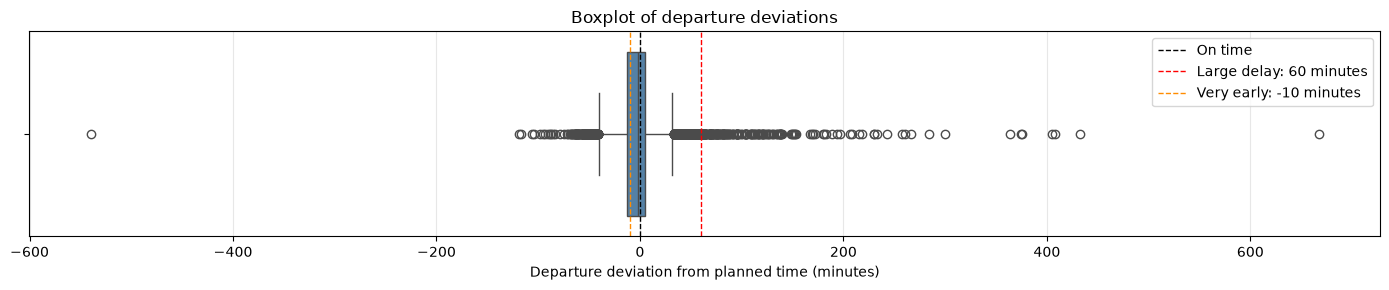

In [135]:
# Ensure the column is numeric
df_vy_timings_filtered["departure_delay"] = pd.to_numeric(
    df_vy_timings_filtered["departure_delay"],
    errors="coerce"
)

plt.figure(figsize=(14, 3))

sns.boxplot(
    x=df_vy_timings_filtered["departure_delay"],
    color="steelblue"
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="On time"
)

plt.axvline(
    60,
    color="red",
    linestyle="--",
    linewidth=1,
    label="Large delay: 60 minutes"
)

plt.axvline(
    -10,
    color="darkorange",
    linestyle="--",
    linewidth=1,
    label="Very early: -10 minutes"
)

plt.title("Boxplot of departure deviations")
plt.xlabel("Departure deviation from planned time (minutes)")
plt.legend()
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [136]:
delay = df_vy_timings_filtered["departure_delay"].dropna()

q1 = delay.quantile(0.25)
q3 = delay.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

boxplot_outliers = df_vy_timings_filtered[
    (df_vy_timings_filtered["departure_delay"] < lower_bound) |
    (df_vy_timings_filtered["departure_delay"] > upper_bound)
].sort_values("departure_delay")

print(f"Lower outlier bound: {lower_bound:.2f} minutes")
print(f"Upper outlier bound: {upper_bound:.2f} minutes")
print(f"Number of boxplot outliers: {len(boxplot_outliers)}")

boxplot_outliers[
    [
        "LoggTogID",
        "train_id",
        "train_date",
        "scheduled_departure_time",
        "actual_departure_time",
        "departure_delay"
    ]
]

Lower outlier bound: -40.00 minutes
Upper outlier bound: 32.00 minutes
Number of boxplot outliers: 565


,LoggTogID,train_id,train_date,scheduled_departure_time,actual_departure_time,departure_delay
14421,10-11-2025_5709,5709,2025-11-10,2025-11-10T20:12:00.000Z,2025-11-10T11:12:00.000Z,-540.0
1208,24-08-2026_91971,91971,2026-08-24,2026-08-24T11:36:00.000Z,2026-08-24T09:37:00.000Z,-119.0
1846,10-08-2026_5266,5266,2026-08-10,2026-08-10T10:54:00.000Z,2026-08-10T08:57:00.000Z,-117.0
1257,22-08-2026_85267,85267,2026-08-22,2026-08-22T21:40:00.000Z,2026-08-22T19:54:00.000Z,-106.0
2887,20-07-2026_5707,5707,2026-07-20,2026-07-20T15:12:00.000Z,2026-07-20T13:28:00.000Z,-104.0
...,...,...,...,...,...,...
19821,04-08-2025_5707,5707,2025-08-04,2025-08-04T15:12:00.000Z,2025-08-04T21:28:00.000Z,376.0
3100,15-07-2026_5707,5707,2026-07-15,2026-07-15T15:12:00.000Z,2026-07-15T21:57:00.000Z,405.0
7816,07-04-2026_4911,4911,2026-04-07,2026-04-07T07:22:00.000Z,2026-04-07T14:10:00.000Z,408.0
2992,17-07-2026_5735,5735,2026-07-17,2026-07-17T20:35:00.000Z,2026-07-18T03:48:00.000Z,433.0


##### Data types/formats

In [137]:
df_vy_timings_filtered.tail()

,train_id,train_date,cancelled,scheduled_departure_time,actual_departure_time,actual_arrival_time,estimated_arrival_time,just_passing_through,departure_delay,train_company,LoggTogID
19942,5735,2025-08-01,N,2025-08-01T20:42:00.000Z,2025-08-01T20:43:00.000Z,NaN,NaN,False,1.0,CN,01-08-2025_5735
19943,68340,2025-08-01,N,2025-08-01T18:26:00.000Z,2025-08-01T18:14:00.000Z,NaN,NaN,False,-12.0,CN,01-08-2025_68340
19945,81914,2025-08-01,N,2025-08-01T13:07:00.000Z,2025-08-01T12:48:00.000Z,NaN,NaN,False,-19.0,CN,01-08-2025_81914
19948,85805,2025-08-01,N,2025-08-01T11:30:00.000Z,2025-08-01T11:25:00.000Z,NaN,NaN,False,-5.0,CN,01-08-2025_85805
19950,85811,2025-08-01,N,2025-08-01T16:30:00.000Z,2025-08-01T16:30:00.000Z,NaN,NaN,False,0.0,CN,01-08-2025_85811


In [138]:
# Check data types
df_vy_timings_filtered.dtypes

train_id                             int64
train_date                  datetime64[us]
cancelled                              str
scheduled_departure_time               str
actual_departure_time                  str
actual_arrival_time                    str
estimated_arrival_time                 str
just_passing_through                  bool
departure_delay                    float64
train_company                          str
LoggTogID                              str
dtype: object

The selected columns mostly have suitable data types and formats for further analysis. `train_id` is numeric and should be converted to string, `train_date` is stored as a datetime, `just_passing_through` is Boolean, `departure_delay` is numeric, and `LoggTogID` follows the expected DD-MM-YYYY_train_id format. The `cancelled` and `train_company` columns contain categorical string values. The scheduled and actual departure times, together with the actual and estimated arrival times, are stored as ISO 8601 timestamp strings and should be converted to `Europe/Oslo` datetime before performing time-based calculations. The arrival columns are included to distinguish arrival-only trains from trains relevant to the departure analysis. Missing values in the time columns are handled separately in the missing-value analysis.

### Summary and final verdict of this dataset

The Vy timings dataset originally contained 19,952 rows covering the period from 01-08-2025 to 16-09-2026. After excluding cancelled trains, trains that were just passing through, and rows identified as arrival-only based on the arrival timestamps, 4,968 rows remained for the departure analysis. The arrival-only trains, comprising 4,597 rows, were stored separately for traceability.

The departure-analysis table represents 406 of 412 dates. The missing dates include dates where the available rows were arrival-only, as well as 04-04-2026 and 05-04-2026, which were checked against the terminal logs and had only cancelled trains. The missing dates are therefore explainable, but the date coverage should be documented clearly.

No blank rows or fully duplicate rows were found. `LoggTogID` is non-missing and should be unique for the 4,968 rows in the updated departure-analysis table. The grain is therefore one row per departure, provided that the uniqueness check is rerun after excluding the arrival-only rows.

The departure-time completeness check shows that 4,703 rows have both scheduled and actual departure times. A further 151 rows have a scheduled departure without a registered actual departure, while one row has an actual departure without a scheduled departure. The remaining 113 rows have neither departure time nor arrival time and require further investigation. The 4,597 rows with missing departure times and arrival information were identified as arrival-only trains and excluded from the departure analysis. No rows were found where both departure times were present but `departure_delay` was missing.

The departure-delay data contains extreme values. The boxplot identified 565 statistical outliers before arrival-only trains were excluded. This check should be rerun on the updated departure-analysis table so that the outlier count only describes actual departure records. The extreme observations should not be removed automatically, but investigated as possible operational edge cases or data-quality issues.

**Final verdict:** The dataset is suitable as a basis for departure analysis after distinguishing arrival-only trains from departure records. The updated departure-analysis table has the intended grain of one row per `LoggTogID`, subject to rerunning the uniqueness check after filtering. However, the 113 rows without either arrival or departure information, the 151 rows without an actual departure, the one row without a scheduled departure, and the extreme departure deviations should be handled explicitly before further analysis. The data types and timestamp formats should also be converted to the preferred variants.

## ExcelReport-6f2dcb04-d1bc-4d7e-b997-cbd3a93fe1b3


### Qualitative aspects

**Data collection procedure:** 
- A -- Automatically generated report from the TIOS systems, of all CargoNet delayed trains
- B -- Time data is automatically generated based on source data by sensors and internal systems at Bane NOR and in the infrastructure
- C -- Delay code and comments are inputted manually by TXP operator (traffic control at Bane NOR).

**Comment:**
- A & B -- The time data should be reliable and be able to represent actual delay time
- C -- The delay code might still be vulnerable to subjective interpretations of the TXP operator, but the comments might explain the reason of choosing the particular code.

**Relevant columns to use:**
- 'Dato'
- 'Tognr'
- (Construct a LoggTogID of dato+tognr)
- 'Innstilt'
- 'Forsinkelse'
- 'Årsak'
- 'HL-beskrivelse'
- 'Kommentar'

### Quantitative aspects

#### Preparation

In [139]:
# Import
df_TIOS_delays_report = pd.read_csv("../data/ExcelReport-6f2dcb04-d1bc-4d7e-b997-cbd3a93fe1b3.csv", sep=";", encoding="utf-8-sig")


In [140]:
# Define the inclusive date interval
start_date = pd.Timestamp("2025-08-01")
end_date = pd.Timestamp("2026-09-16")

# Convert Avgangsdato in both dataframes
df_TIOS_delays_report["Dato"] = pd.to_datetime(
    df_TIOS_delays_report["Dato"],
    format="%d.%m.%Y",
    errors="coerce"
)

# Filter the combined dataset based on time period
df_tios_delays_filtered = (
    df_TIOS_delays_report[
        df_TIOS_delays_report["Dato"].between(
            start_date,
            end_date,
            inclusive="both"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

In [141]:
print("Number of rows:", len(df_tios_delays_filtered))
print(
    "Date range:",
    df_tios_delays_filtered["Dato"].min(),
    "to",
    df_tios_delays_filtered["Dato"].max()
)
print(df_tios_delays_filtered["Dato"].dtype)

Number of rows: 1816
Date range: 2025-08-01 00:00:00 to 2026-09-15 00:00:00
datetime64[us]


In [142]:
# Select the relevant columns for further analysis
relevant_columns = [
    "Dato",
    "Tognr",
    "Innstilt",
    "Årsak",
    "HL-beskrivelse",
    "Kommentar"
]

df_tios_delays_filtered = (
    df_tios_delays_filtered[relevant_columns]
    .copy()
)

In [143]:
# Check filtering
print("Dimensions of filtered table:", df_tios_delays_filtered.shape)
df_tios_delays_filtered.columns.tolist()

Dimensions of filtered table: (1816, 6)


['Dato', 'Tognr', 'Innstilt', 'Årsak', 'HL-beskrivelse', 'Kommentar']

#### Actual analysis

##### Data types/formats

##### Expected dates for analysis period
- All dates covered?
- Any gaps in the middle of the study period?

##### Row level contents
- Blank rows?
- Duplicate rows?
- Rows w/o train ID (Tognummer)?
- Planned departures w/o actual departure times?
- Actual departures w/o planned departure?

##### Column level contents - missing values
- For each relevant, chosen column ^^
- (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code)

##### Grain uniqueness and duplicates

##### Scope of edge cases
- Overnight departures
- Outliers
    - Very large delays
    - Very early departures (deviation from planned)

### Summary and final verdict of this dataset

## Årsakskodelister (IKKE REDIGER!

### Qualitative aspects

**Data collection procedure:** 
- A -- 

**Comment:**


**Relevant columns to use:**
- A

### Quantitative aspects

#### Preparation

In [144]:
# # Define the inclusive date interval
# start_date = pd.Timestamp("2025-08-01")
# end_date = pd.Timestamp("2026-09-16")

In [145]:
# print("Number of rows:", len(df_terminallogg_filtered))
# print(
#     "Date range:",
#     df_terminallogg_filtered["Avgangsdato"].min(),
#     "to",
#     df_terminallogg_filtered["Avgangsdato"].max()
# )
# print(df_terminallogg_filtered["Avgangsdato"].dtype)

In [146]:
# # Select the relevant columns for further analysis
# relevant_columns = [
#     "Column name"
# ]

# df_terminallogg_filtered = (
#     df_terminallogg_filtered[relevant_columns]
#     .copy()
# )

In [147]:
# # Check filtering
# print("Dimensions of filtered table:", df_terminallogg_filtered.shape)
# df_terminallogg_filtered.columns.tolist()

#### Actual analysis

##### Data types/formats

##### Expected dates for analysis period
- All dates covered?
- Any gaps in the middle of the study period?

##### Row level contents
- Blank rows?
- Duplicate rows?
- Rows w/o train ID (Tognummer)?
- Planned departures w/o actual departure times?
- Actual departures w/o planned departure?

##### Column level contents - missing values
- For each relevant, chosen column ^^
- (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code)

##### Grain uniqueness and duplicates

##### Scope of edge cases
- Overnight departures
- Outliers
    - Very large delays
    - Very early departures (deviation from planned)

### Summary and final verdict of this dataset

## Terminallogg R25 and R26
*Combined R25 and R26 datasets as a result of the findings of the data exploration*

### Qualitative aspects

**Data collection procedure:** 
- A -- Content should contain all expected CargoNet train departures from Alnabru in the R25 and R26 calendar
- B -- Input data are mostly done manually in excel-sheets
- C -- Excel columns have strict data validation turned on to ensure proper formats
- D -- Some columns are calculated automatically using formulas (f.eks. the ones regarding 'Avvik' and 'LoggTogID')  

**Comment:**
- A -- the datasets works as a basis of which train departures to analyze, i.e. the datasets here are the ones to analyze for R25 and R26
- B & C -- The input is done manually and not automatically, and only the formatting is validated, not the actual content of the values. That makes the input values still vulnerable for wrong input values, typos, operator faults and/or routines for consistent/standardized inputs. This especially goes for timestamps, where one should do a quantitative assesment as well, to check the scope of data quality issues regarding the actual inputs. 
The 'Årsakskode'-column have more strict validation where users must choose from a list and can be considered to have a higher probability of "correct" input values, although the choice of code is done by the operator and thus dependent/vulnerable on their subjective interpretation.
- D -- The automatically calculated columns are dependent on input of other columns. These might still be used, but the formulas from here can easily be replicated and might rather be calculated again in this study for consistent calculations. 

**Relevant columns to use:**
- 'Merknad'
- 'Tognummer'
- 'Avgangsdato'
- 'Lastefrist'
- 'Ferdig opplastet'
- 'Frist lok'
- 'Lok ankommet'
- 'Planlagt klart fra terminal'
- 'Klart fra terminal'
- 'Planlagt avgang'
- 'Faktisk avgang'
- 'Årsakskode - avgangsforsinkelse'
- 'Kommentar'
- 'LoggTogID'

### Quantitative aspects

#### Preparation

In [148]:
# Import both datasets
df_terminallogg_r25 = pd.read_csv(
    "../data/Terminallogg R25.csv",
    sep=";",
    encoding="utf-8-sig"
)

df_terminallogg_r26 = pd.read_csv(
    "../data/Terminallogg R26.csv",
    sep=";",
    encoding="utf-8-sig"
)

In [149]:
# Define the inclusive date interval
start_date = pd.Timestamp("2025-08-01")
end_date = pd.Timestamp("2026-09-16")

# Convert Avgangsdato in both dataframes
for df in [df_terminallogg_r25, df_terminallogg_r26]:
    df["Avgangsdato"] = pd.to_datetime(
        df["Avgangsdato"],
        format="%Y-%m-%d %H:%M:%S",
        errors="coerce"
    )

# Combine the datasets
df_terminallogg = pd.concat(
    [df_terminallogg_r25, df_terminallogg_r26],
    ignore_index=True
)

# Filter the combined dataset based on time period
df_terminallogg_filtered = (
    df_terminallogg[
        df_terminallogg["Avgangsdato"].between(
            start_date,
            end_date,
            inclusive="both"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

In [150]:
print("Number of rows:", len(df_terminallogg_filtered))
print(
    "Date range:",
    df_terminallogg_filtered["Avgangsdato"].min(),
    "to",
    df_terminallogg_filtered["Avgangsdato"].max()
)
print(df_terminallogg_filtered["Avgangsdato"].dtype)

Number of rows: 2340
Date range: 2025-08-01 00:00:00 to 2025-12-28 00:00:00
datetime64[us]


In [151]:
# Select the relevant columns for further analysis
relevant_columns = [
    "Merknad",
    "Tognummer",
    "Avgangsdato",
    "Lastefrist",
    "Ferdig opplastet",
    "Frist lok",
    "Lok ankommet",
    "Planlagt klart fra terminal",
    "Klart fra terminal",
    "Planlagt avgang",
    "Faktisk avgang",
    "Årsakskode - avgangsforsinkelse",
    "Kommentar",
    "LoggTogID"
]

df_terminallogg_filtered = (
    df_terminallogg_filtered[relevant_columns]
    .copy()
)

In [152]:
# Check filtering
print("Dimensions of filtered table:", df_terminallogg_filtered.shape)
df_terminallogg_filtered.columns.tolist()

Dimensions of filtered table: (2340, 14)


['Merknad',
 'Tognummer',
 'Avgangsdato',
 'Lastefrist',
 'Ferdig opplastet',
 'Frist lok',
 'Lok ankommet',
 'Planlagt klart fra terminal',
 'Klart fra terminal',
 'Planlagt avgang',
 'Faktisk avgang',
 'Årsakskode - avgangsforsinkelse',
 'Kommentar',
 'LoggTogID']

#### Actual analysis

In [153]:
# See all columns and their datatypes
df_terminallogg_filtered.dtypes

Merknad                                       str
Tognummer                                 float64
Avgangsdato                        datetime64[us]
Lastefrist                                    str
Ferdig opplastet                              str
Frist lok                                     str
Lok ankommet                                  str
Planlagt klart fra terminal                   str
Klart fra terminal                            str
Planlagt avgang                               str
Faktisk avgang                                str
Årsakskode - avgangsforsinkelse               str
Kommentar                                     str
LoggTogID                                     str
dtype: object

##### Data types/formats

##### Expected dates for analysis period
- All dates covered?
- Any gaps in the middle of the study period?

##### Row level contents
- Blank rows?
- Duplicate rows?
- Rows w/o train ID (Tognummer)?
- Planned departures w/o actual departure times?
- Actual departures w/o planned departure?

##### Column level contents - missing values
- For each relevant, chosen column ^^
- (Distignuish between if missing values are ok or not, e.g. punctual departures have no delay code)

##### Grain uniqueness and duplicates

##### Scope of edge cases
- Overnight departures
- Outliers
    - Very large delays
    - Very early departures (deviation from planned)

### Summary and final verdict of this dataset

## Combined dataset: one-big-table